# DWD-Wetteranalyse Berlin

Dieses Notebook wertet die heruntergeladene CSV-Datei `dwd_berlin_2020_bis_2026-11-01.csv` aus. Sie enthält tägliche DWD-Messungen der Station **Berlin-Dahlem (FU), 00403** vom 01.01.2020 bis zum letzten verfügbaren Tag **01.11.2026**.

Die Datei enthält 2.497 Kalendertage. Davon sind 2.481 Werte für Minimum, Maximum und Tagesmitteltemperatur, 2.482 Niederschlagswerte und 2.481 Sonnenscheindauerwerte vorhanden. Leere Felder sind fehlende DWD-Messungen und werden nicht künstlich ergänzt.

Quelle: [DWD Climate Data Center, Tageswerte](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/). Die CSV muss im selben Ordner wie dieses Notebook liegen.

## 1. Bibliotheken vorbereiten

Pandas liest und untersucht die CSV, Matplotlib zeichnet die Zeitreihen. Führe die Installationszeile bei Bedarf einmal aus.

In [12]:
%pip install pandas matplotlib

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

Note: you may need to restart the kernel to use updated packages.


## 2. CSV laden

Lies die bereits heruntergeladene Tagesdatei ein. Die Datumsspalte wird als Datumsindex gesetzt, damit Pandas Zeitreihenfunktionen verwenden kann.

In [13]:
csv_datei = Path("dwd_berlin_2020_bis_2026-11-01.csv")
if not csv_datei.exists():
    raise FileNotFoundError(f"CSV nicht gefunden: {csv_datei.resolve()}")

wetter = pd.read_csv(csv_datei, parse_dates=["datum"], index_col="datum")
wetter = wetter.sort_index()

messgroessen = ["temp_min_c", "temp_max_c", "temp_mean_c", "niederschlag_mm", "sonnenstunden_h"]
assert all(spalte in wetter.columns for spalte in messgroessen)
print("Zeitraum:", wetter.index.min().date(), "bis", wetter.index.max().date())
print("Kalendertage:", len(wetter))
wetter.head()

Zeitraum: 2020-01-01 bis 2026-11-01
Kalendertage: 2497


,temp_min_c,temp_max_c,temp_mean_c,niederschlag_mm,sonnenstunden_h
datum,,,,,
2020-01-01,-2.8,5.0,1.8,0.0,2.9
2020-01-02,-4.1,6.2,-0.3,0.0,7.5
2020-01-03,0.8,6.9,4.3,4.4,0.0
2020-01-04,1.7,5.6,4.1,3.0,0.0
2020-01-05,-1.4,3.6,1.4,0.0,2.1


## 3. Datenqualität und erste Exploration

Prüfe, wie viele Werte pro Messgröße vorhanden sind. Fehlende DWD-Werte bleiben fehlend; für einfache Kennzahlen verwendet Pandas automatisch die vorhandenen Messungen.

In [14]:
abdeckung = pd.DataFrame(
    {
        "vorhanden": wetter.notna().sum(),
        "fehlend": wetter.isna().sum(),
        "abdeckung_prozent": (wetter.notna().mean() * 100).round(2),
    }
)
display(abdeckung)
display(wetter.describe().T.round(2))

,vorhanden,fehlend,abdeckung_prozent
temp_min_c,2481,16,99.36
temp_max_c,2481,16,99.36
temp_mean_c,2481,16,99.36
niederschlag_mm,2482,15,99.40
sonnenstunden_h,2481,16,99.36


,count,mean,std,min,25%,50%,75%,max
temp_min_c,2481.0,6.61,6.33,-12.2,1.7,6.7,11.9,21.4
temp_max_c,2481.0,15.65,8.74,-7.2,8.7,15.8,22.5,39.0
temp_mean_c,2481.0,11.09,7.30,-9.0,5.6,10.9,17.1,29.7
niederschlag_mm,2482.0,1.44,3.45,0.0,0.0,0.0,1.2,44.6
sonnenstunden_h,2481.0,5.63,4.66,0.0,1.0,5.1,9.5,16.1


## 4. Temperaturverlauf

Das Band zeigt die tägliche Spanne zwischen Minimum und Maximum. Die Linien zeigen Tagesmitteltemperatur und deren gleitenden 30-Tage-Mittelwert.

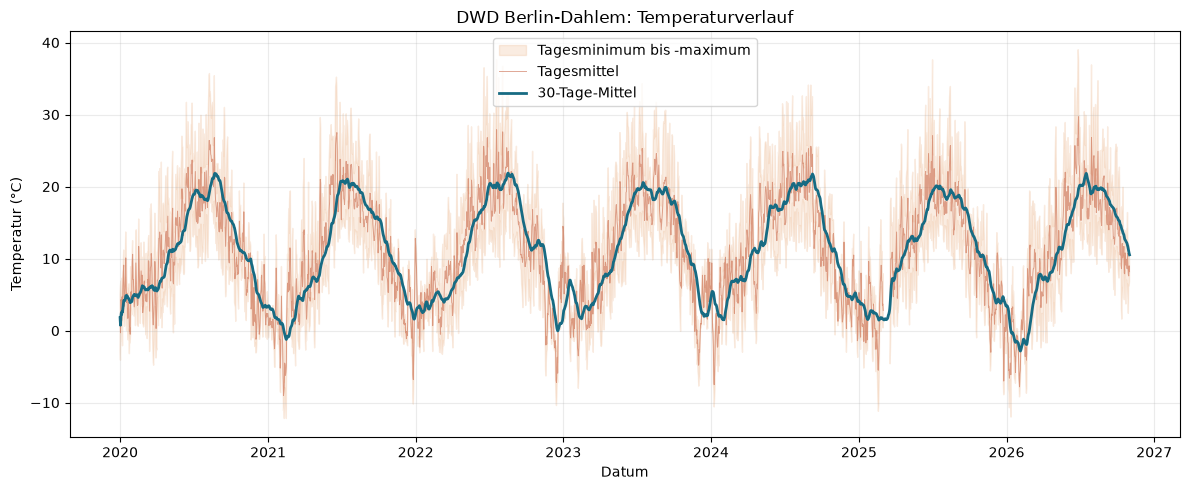

In [15]:
mittel_30_tage = wetter["temp_mean_c"].rolling(30, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(wetter.index, wetter["temp_min_c"], wetter["temp_max_c"], color="#e6a16c", alpha=0.2, label="Tagesminimum bis -maximum")
ax.plot(wetter.index, wetter["temp_mean_c"], color="#c65f3e", linewidth=0.7, alpha=0.55, label="Tagesmittel")
ax.plot(wetter.index, mittel_30_tage, color="#176b83", linewidth=2, label="30-Tage-Mittel")
ax.set_title("DWD Berlin-Dahlem: Temperaturverlauf")
ax.set_xlabel("Datum")
ax.set_ylabel("Temperatur (°C)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 5. Niederschlag pro Tag

Die Säulen zeigen die gemessene Niederschlagsmenge pro Tag. Zusätzlich fassen wir die Werte zu Monatssummen zusammen, um saisonale Unterschiede sichtbar zu machen. Fehlende Messungen erscheinen als Lücken.

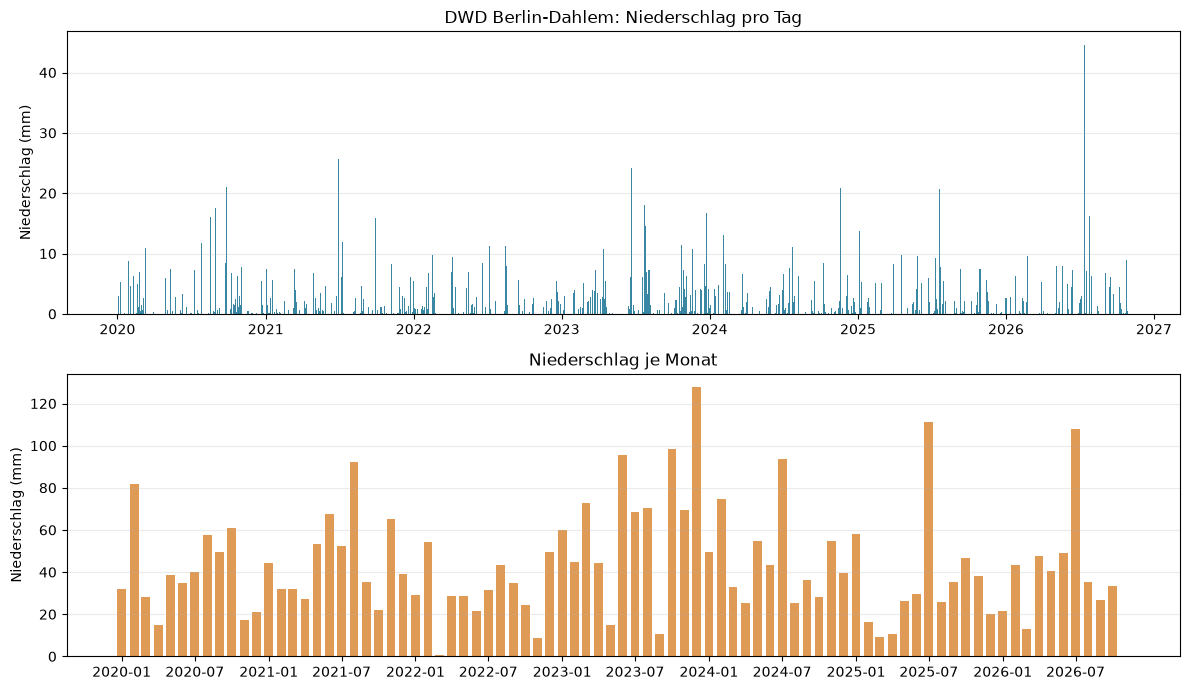

In [16]:
niederschlag_monat = wetter["niederschlag_mm"].resample("MS").sum(min_count=1)

fig, achsen = plt.subplots(2, 1, figsize=(12, 7))
achsen[0].bar(wetter.index, wetter["niederschlag_mm"], width=1.0, color="#3987a3")
achsen[0].set_title("DWD Berlin-Dahlem: Niederschlag pro Tag")
achsen[0].set_ylabel("Niederschlag (mm)")
achsen[0].grid(axis="y", alpha=0.25)

achsen[1].bar(niederschlag_monat.index, niederschlag_monat.values, width=22, color="#df9a55")
achsen[1].set_xticks(niederschlag_monat.index[::6], niederschlag_monat.index.strftime("%Y-%m")[::6])
achsen[1].set_title("Niederschlag je Monat")
achsen[1].set_ylabel("Niederschlag (mm)")
achsen[1].grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Sonnenscheindauer und Extremtage

Die tägliche Sonnenscheindauer wird mit einem 30-Tage-Mittel dargestellt. Zum Abschluss ermitteln wir die kälteste Mindesttemperatur, höchste Höchsttemperatur, das größte Tagesmittel, den stärksten Tagesniederschlag und die meisten Sonnenstunden. Fehlwerte werden bei diesen Berechnungen übersprungen.

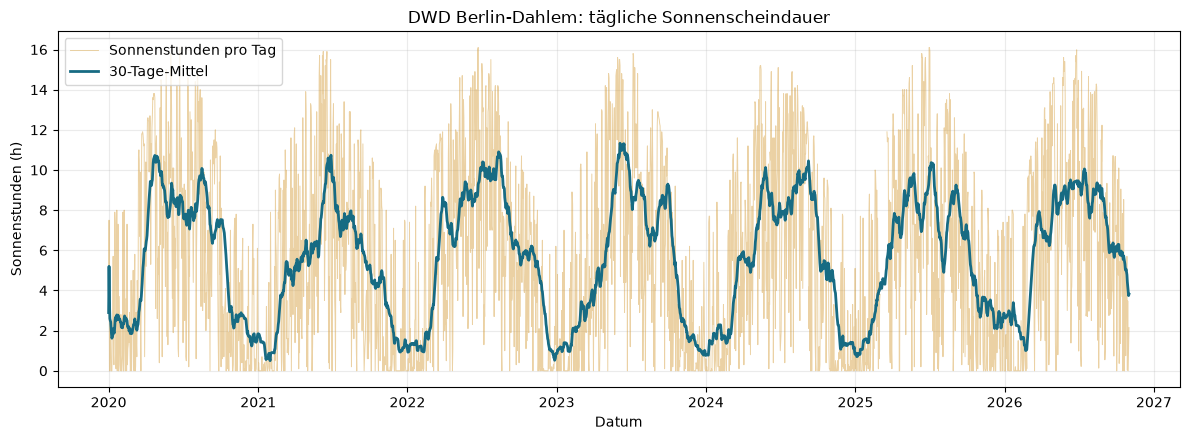

,Ereignis,Datum,Messwert
0,Kältester Tag (Tagesminimum),2021-02-10,-12.2 °C
1,Wärmster Tag (Tagesmaximum),2026-06-27,39.0 °C
2,Höchstes Tagesmittel,2026-06-28,29.7 °C
3,Stärkster Tagesniederschlag,2026-07-14,44.6 mm
4,Meiste Sonnenstunden,2020-06-23,16.1 h


In [17]:
sonnen_30_tage = wetter["sonnenstunden_h"].rolling(30, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(wetter.index, wetter["sonnenstunden_h"], color="#d39b35", linewidth=0.7, alpha=0.45, label="Sonnenstunden pro Tag")
ax.plot(wetter.index, sonnen_30_tage, color="#176b83", linewidth=2, label="30-Tage-Mittel")
ax.set_title("DWD Berlin-Dahlem: tägliche Sonnenscheindauer")
ax.set_xlabel("Datum")
ax.set_ylabel("Sonnenstunden (h)")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

extremwerte = pd.DataFrame(
    [
        {"Ereignis": "Kältester Tag (Tagesminimum)", "Datum": wetter["temp_min_c"].idxmin(), "Messwert": f"{wetter['temp_min_c'].min():.1f} °C"},
        {"Ereignis": "Wärmster Tag (Tagesmaximum)", "Datum": wetter["temp_max_c"].idxmax(), "Messwert": f"{wetter['temp_max_c'].max():.1f} °C"},
        {"Ereignis": "Höchstes Tagesmittel", "Datum": wetter["temp_mean_c"].idxmax(), "Messwert": f"{wetter['temp_mean_c'].max():.1f} °C"},
        {"Ereignis": "Stärkster Tagesniederschlag", "Datum": wetter["niederschlag_mm"].idxmax(), "Messwert": f"{wetter['niederschlag_mm'].max():.1f} mm"},
        {"Ereignis": "Meiste Sonnenstunden", "Datum": wetter["sonnenstunden_h"].idxmax(), "Messwert": f"{wetter['sonnenstunden_h'].max():.1f} h"},
    ]
)
display(extremwerte)